In [ ]:
# The purpose of this notebook is to inspect distributions of target variables 

In [6]:
# import the data

from pathlib import Path
import pandas as pd
import numpy as np

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "Dry Strength Mean",
    "Wet Strength Mean",
]
measured_se_cols = [
    "Avg_Density SE",
    "Dry Strength SE",
    "Wet Strength SE",
]

# Keep each target beside its standard error column
measured_cols = [
    col
    for target, se in zip(measured_target_cols, measured_se_cols)
    for col in (target, se)
]
df = df.loc[:, formula_cols + measured_cols]

df["std_Avg_Density_g_cm3"] = df["Avg_Density SE"] * np.sqrt(3)
df["std_Dry Strength Mean"] = df["Dry Strength SE"] * np.sqrt(3)
df["std_Wet Strength Mean"] = df["Wet Strength SE"] * np.sqrt(3)

print(df.head())

import pandas as pd

# Display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

df

   TEM  Joncryl  NC513  PEG-DE  NGDE  Avg_Density_g_cm3  Avg_Density SE  \
0    8      NaN    NaN     NaN   NaN           0.192000        0.002667   
1    8      0.7    NaN     NaN   NaN           0.195000        0.007263   
2    8      1.0    NaN     NaN   NaN           0.159000        0.005033   
3    8      1.5    NaN     NaN   NaN           0.159933        0.004410   
4    8      2.0    NaN     NaN   NaN           0.201000        0.008817   

   Dry Strength Mean  Dry Strength SE  Wet Strength Mean  Wet Strength SE  \
0          53.674733         1.008133          23.680000         0.200000   
1          68.863717         4.243165          24.258481         1.187076   
2          50.405845         2.550662          21.329450         1.916881   
3          54.717605         0.566776          20.183592         0.276639   
4          85.787785         6.781653          27.585357         2.274881   

   std_Avg_Density_g_cm3  std_Dry Strength Mean  std_Wet Strength Mean  
0            

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,Avg_Density SE,Dry Strength Mean,Dry Strength SE,Wet Strength Mean,Wet Strength SE,std_Avg_Density_g_cm3,std_Dry Strength Mean,std_Wet Strength Mean
0,8,NaN,NaN,NaN,NaN,0.192000,0.002667,53.674733,1.008133,23.680000,0.200000,0.004619,1.746138,0.346410
1,8,0.7,NaN,NaN,NaN,0.195000,0.007263,68.863717,4.243165,24.258481,1.187076,0.012580,7.349378,2.056076
2,8,1.0,NaN,NaN,NaN,0.159000,0.005033,50.405845,2.550662,21.329450,1.916881,0.008718,4.417877,3.320135
3,8,1.5,NaN,NaN,NaN,0.159933,0.004410,54.717605,0.566776,20.183592,0.276639,0.007638,0.981684,0.479154
4,8,2.0,NaN,NaN,NaN,0.201000,0.008817,85.787785,6.781653,27.585357,2.274881,0.015271,11.746168,3.940210
5,8,3.0,NaN,NaN,NaN,0.202000,0.006807,80.535443,3.474368,27.921901,1.266235,0.011790,6.017782,2.193183
6,5,NaN,NaN,NaN,NaN,0.298930,0.001613,157.659876,2.948774,51.133703,1.236393,0.002794,5.107426,2.141495
7,5,NaN,0.7,NaN,NaN,0.360035,0.001748,215.989325,6.779771,82.812461,4.037828,0.003028,11.742908,6.993724
8,5,NaN,1.0,NaN,NaN,0.355557,0.002226,218.543779,5.777923,77.134354,1.777061,0.003855,10.007656,3.077961
9,5,NaN,2.0,NaN,NaN,0.358055,0.005455,196.341194,4.896257,76.406460,2.335764,0.009448,8.480566,4.045661


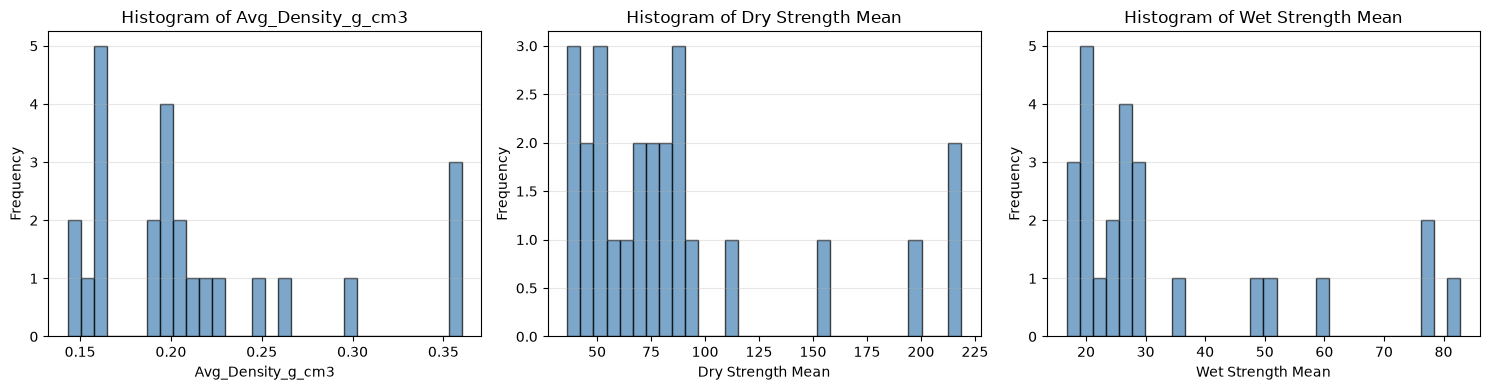

In [3]:
# inspect the distribution of density, wet and dry strength

import matplotlib.pyplot as plt

measured_target_cols = [
    "Avg_Density_g_cm3",
    "Dry Strength Mean",
    "Wet Strength Mean",
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, col in enumerate(measured_target_cols):
    axes[idx].hist(df[col], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[idx].set_xlabel(col)
    axes[idx].set_ylabel('Frequency')
    axes[idx].set_title(f'Histogram of {col}')
    axes[idx].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

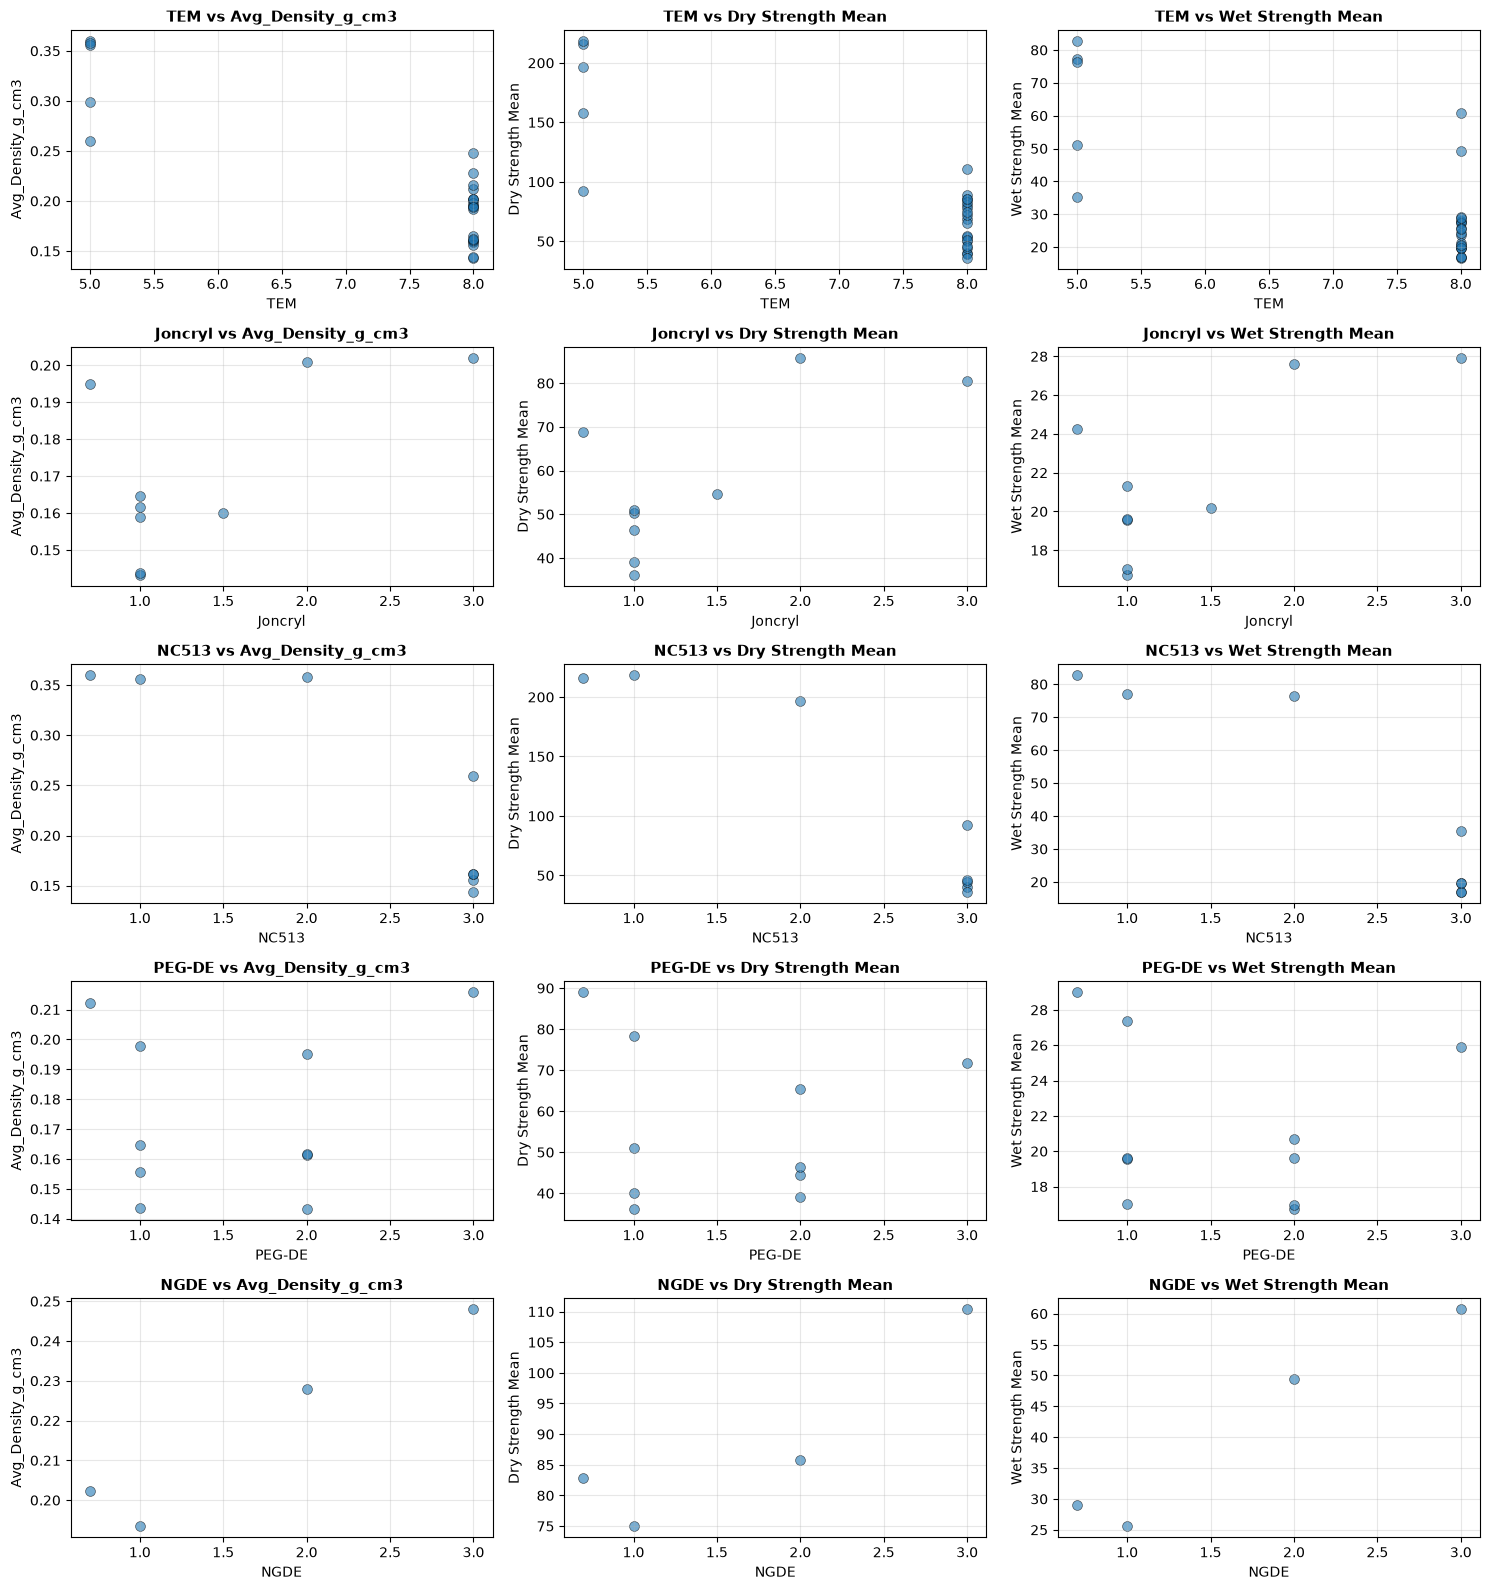

In [5]:
# look at formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"] vs density, dry and wet strength

import matplotlib.pyplot as plt
import numpy as np

formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "Dry Strength Mean",
    "Wet Strength Mean",
]

# Create a 5x3 grid of subplots (5 formula cols, 3 measured targets)
fig, axes = plt.subplots(5, 3, figsize=(15, 16))

for i, formula_col in enumerate(formula_cols):
    for j, target_col in enumerate(measured_target_cols):
        ax = axes[i, j]
        
        # Create scatter plot
        ax.scatter(df[formula_col], df[target_col], alpha=0.6, s=50, edgecolors='k', linewidth=0.5)
        
        # Add labels and title
        ax.set_xlabel(formula_col, fontsize=10)
        ax.set_ylabel(target_col, fontsize=10)
        ax.set_title(f'{formula_col} vs {target_col}', fontsize=11, fontweight='bold')
        
        # Add grid
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()